# 03 — Autoencoder (Unsupervised, BENIGN-Only Anomaly Detector)

Third member of the ML ensemble (Isolation Forest + Random Forest + Autoencoder, combined
later in the Fusion Layer — not built here). This notebook builds and evaluates **only** the
Autoencoder, on CICIDS-2017. UNSW-NB15 is left for the later cross-dataset stage.

Unlike Isolation Forest (trained on the full mixed train set, no label used at all) and
Random Forest (supervised, trained on every class), the Autoencoder is trained **only on
BENIGN rows** — it learns to reconstruct normal traffic well, and high reconstruction error
on unseen traffic is the anomaly signal. This is a different unsupervised strategy than
Isolation Forest's isolation-based scoring, so a central question this notebook answers is:
**does the Autoencoder's blind-spot profile look similar to Isolation Forest's (redundant),
or different (real diversity for the ensemble's unsupervised half)?** §9 makes this
comparison directly.

Findings from the first two ensemble members, for reference:
- **Isolation Forest** (tuned, `contamination=0.20`): val Precision 0.529 / Recall 0.556 /
  F1 0.542 / AUC-ROC 0.729. Detects flood-style DoS/DDoS well (61–90% recall, including
  zero-day/LOAO) but is structurally blind to FTP-Patator/SSH-Patator/PortScan/Bot (near-0%
  recall regardless of threshold).
- **Random Forest** (supervised, SMOTE-resampled train): val binary roll-up Precision 0.9955
  / Recall 0.9958 / F1 0.9957 / AUC-ROC 0.9998. Compensates decisively for exactly the
  categories Isolation Forest misses, but collapses on flood attacks it never saw in LOAO
  zero-day testing (e.g. DoS Hulk in-dataset 0.997 → LOAO 0.012) — the opposite failure mode.

## 1. Setup

In [1]:
# Anaconda's numpy/scikit-learn stack and the pip-installed CPU torch wheel both bundle
# their own copy of the Intel OpenMP runtime (libiomp5md.dll) on this machine, which torch
# refuses to initialize twice by default. This is a packaging redundancy, not a correctness
# issue for the single-process, non-conflicting numeric work this notebook does, so the
# workaround is safe here -- must be set before the first `import torch`.
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 160)

print("torch version:", torch.__version__, " | cuda available:", torch.cuda.is_available())

torch version: 2.12.1+cu130  | cuda available: True


In [2]:
# Repo root is the parent of this notebook's directory when opened normally from
# `notebooks/` -- same convention as 01_isolation_forest.ipynb / 02_random_forest.ipynb.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_PROCESSED_DIR = ROOT / "data" / "processed"
DATA_FEATURES_DIR = ROOT / "data" / "features"
LOAO_DIR = ROOT / "data" / "processed" / "loao"
MODELS_DIR = ROOT / "models"
REPORTS_DIR = ROOT / "reports"

print("ROOT:", ROOT)

ROOT: E:\thesis


In [3]:
HIDDEN_DIMS = [64, 32]     # encoder hidden layer sizes, in encoder order; decoder mirrors in reverse
BOTTLENECK_DIM = 16
ACTIVATION = "relu"
LEARNING_RATE = 1e-3
EPOCHS = 30
BATCH_SIZE = 2048
WEIGHT_DECAY = 0.0
EARLY_STOPPING_PATIENCE = 5
BENIGN_INTERNAL_VAL_FRAC = 0.10   # held-out slice of BENIGN train rows, for training-time loss monitoring only
RANDOM_STATE = 42
DEVICE = torch.device("cuda")

# Candidate cutoffs, as percentiles of the val-set BENIGN reconstruction-error distribution
# (mirrors 01_isolation_forest.ipynb's contamination sweep -- a small, auditable grid rather
# than an unconstrained search).
THRESHOLD_PERCENTILES = [90, 95, 99]

AE_CONFIG = {
    "hidden_dims": HIDDEN_DIMS,
    "bottleneck_dim": BOTTLENECK_DIM,
    "activation": ACTIVATION,
    "learning_rate": LEARNING_RATE,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "weight_decay": WEIGHT_DECAY,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
}

torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

In [4]:
train_df = pd.read_parquet(DATA_FEATURES_DIR / "cicids2017_features_train.parquet")
val_df = pd.read_parquet(DATA_FEATURES_DIR / "cicids2017_features_val.parquet")

print("train_df shape:", train_df.shape)
print("val_df shape  :", val_df.shape)

train_df shape: (1780264, 89)
val_df shape  : (504160, 89)


## 2. Feature selection

In [5]:
# Same exclusion rule as 01_isolation_forest.ipynb / 02_random_forest.ipynb: exclude the
# label and MITRE reference columns, including the 4 CTI-encoded columns
# (technique_id_encoded, tactic_encoded, mapping_confidence_encoded, is_known_technique) --
# confirmed during the Isolation Forest leakage fix to be deterministic functions of the true
# Label/attack_cat via label_builder.py's static MITRE lookup, and therefore not legitimate
# detection-time features for any of the three ensemble models.
NON_FEATURE_COLS = [
    "Label", "attack_cat", "technique_id", "technique_name", "tactic", "mapping_confidence",
    "technique_id_encoded", "tactic_encoded", "mapping_confidence_encoded", "is_known_technique",
]

def select_feature_columns(df, non_feature_cols=NON_FEATURE_COLS):
    return [
        c for c in df.columns
        if c not in non_feature_cols and pd.api.types.is_numeric_dtype(df[c])
    ]

feature_cols = select_feature_columns(train_df)
assert feature_cols == select_feature_columns(val_df), "train/val feature columns must match exactly"

print(f"Model input feature count: {len(feature_cols)}")
print("Feature columns used:")
for c in feature_cols:
    print(" -", c)

Model input feature count: 80
Feature columns used:
 - Destination Port
 - Flow Duration
 - Total Fwd Packets
 - Total Backward Packets
 - Total Length of Fwd Packets
 - Total Length of Bwd Packets
 - Fwd Packet Length Max
 - Fwd Packet Length Min
 - Fwd Packet Length Mean
 - Fwd Packet Length Std
 - Bwd Packet Length Max
 - Bwd Packet Length Min
 - Bwd Packet Length Mean
 - Bwd Packet Length Std
 - Flow Bytes/s
 - Flow Packets/s
 - Flow IAT Mean
 - Flow IAT Std
 - Flow IAT Max
 - Flow IAT Min
 - Fwd IAT Total
 - Fwd IAT Mean
 - Fwd IAT Std
 - Fwd IAT Max
 - Fwd IAT Min
 - Bwd IAT Total
 - Bwd IAT Mean
 - Bwd IAT Std
 - Bwd IAT Max
 - Bwd IAT Min
 - Fwd PSH Flags
 - Bwd PSH Flags
 - Fwd URG Flags
 - Bwd URG Flags
 - Fwd Header Length
 - Bwd Header Length
 - Fwd Packets/s
 - Bwd Packets/s
 - Min Packet Length
 - Max Packet Length
 - Packet Length Mean
 - Packet Length Std
 - Packet Length Variance
 - FIN Flag Count
 - SYN Flag Count
 - RST Flag Count
 - PSH Flag Count
 - ACK Flag Count


In [6]:
assert len(feature_cols) == 80, f"expected 80 features (matching Isolation Forest / Random Forest's set), got {len(feature_cols)}"
print("Confirmed: 80 features, matching 01_isolation_forest.ipynb / 02_random_forest.ipynb's corrected (leakage-free) feature set.")

Confirmed: 80 features, matching 01_isolation_forest.ipynb / 02_random_forest.ipynb's corrected (leakage-free) feature set.


### Confirm feature scaling status

Neural networks are sensitive to unscaled inputs in a way tree-based models (Isolation
Forest, Random Forest) are not, so this needs to be checked directly rather than assumed.
`feature_extractor.py` fits a `MinMaxScaler` on train only (network features only -- not the
sentinel-missing flag columns, which are already 0/1, and not the CTI columns, which are
excluded anyway) and applies the *same* fitted scaler to val/test. That means **train is
guaranteed to be exactly `[0, 1]`**, but **val/test can legitimately fall outside `[0, 1]`**
wherever their values exceed the range the scaler saw during its `fit` on train -- that is
expected behavior for a scaler fit on train only, not a bug or a sign that scaling didn't
happen.

In [7]:
train_desc = train_df[feature_cols].agg(["min", "max"]).T
val_desc = val_df[feature_cols].agg(["min", "max"]).T

n_train_out_of_range = int(((train_desc["min"] < -1e-9) | (train_desc["max"] > 1 + 1e-9)).sum())
print("train columns outside [0, 1]:", n_train_out_of_range, "(expected: 0)")
assert n_train_out_of_range == 0, "train features are not already scaled to [0, 1] -- STOP, do not proceed silently"

val_out_of_range = val_desc[(val_desc["min"] < -1e-9) | (val_desc["max"] > 1 + 1e-9)]
print(f"\nval columns outside [0, 1]: {len(val_out_of_range)} of {len(feature_cols)}")
print("(expected and fine -- MinMaxScaler was fit on train only; unseen val extremes fall outside "
      "the train-derived [0, 1] range. Not rescaling further: reconstruction error naturally grows "
      "for these out-of-range rows, which helps rather than hurts anomaly separation.)")
val_out_of_range

train columns outside [0, 1]: 0 (expected: 0)

val columns outside [0, 1]: 6 of 80
(expected and fine -- MinMaxScaler was fit on train only; unseen val extremes fall outside the train-derived [0, 1] range. Not rescaling further: reconstruction error naturally grows for these out-of-range rows, which helps rather than hurts anomaly separation.)


,min,max
Total Length of Fwd Packets,0.0,5.556805
Bwd Packet Length Mean,0.0,1.327137
Bwd Packet Length Std,0.0,1.220217
Bwd IAT Std,0.0,1.001200
Avg Bwd Segment Size,0.0,1.327137
Subflow Fwd Bytes,0.0,5.544028


In [8]:
print("CONFIRMED: features are already MinMaxScaler-normalized (fit on train only, per feature_extractor.py).")
print("No rescaling needed for the main train/val model below -- load and use as-is.")
print("(The LOAO folds in §10 are a different story -- they predate feature_extractor.py and are raw/unscaled; "
      "flagged and handled separately there.)")

CONFIRMED: features are already MinMaxScaler-normalized (fit on train only, per feature_extractor.py).
No rescaling needed for the main train/val model below -- load and use as-is.
(The LOAO folds in §10 are a different story -- they predate feature_extractor.py and are raw/unscaled; flagged and handled separately there.)


## 3. Prepare BENIGN-only training data

`cicids2017_features_train.parquet` is the capped-SMOTE-resampled file (confirmed in
`02_random_forest.ipynb`: row count grows from 1,512,478 to 1,780,264). SMOTE only
*oversamples* classes below the flat cap -- it does not touch classes already at/above it.
`BENIGN` is CICIDS-2017's majority class by a wide margin, so before assuming it's safe to
filter `Label == "BENIGN"` directly from this file, confirm its row count is identical to the
pre-SMOTE original (`data/processed/cicids2017_train.parquet`) rather than assuming.

In [9]:
pre_smote_train_df = pd.read_parquet(DATA_PROCESSED_DIR / "cicids2017_train.parquet")

n_benign_post_smote = int((train_df["Label"] == "BENIGN").sum())
n_benign_pre_smote = int((pre_smote_train_df["Label"] == "BENIGN").sum())

print("BENIGN rows in post-SMOTE cicids2017_features_train.parquet:", n_benign_post_smote)
print("BENIGN rows in pre-SMOTE  cicids2017_train.parquet         :", n_benign_pre_smote)

assert n_benign_post_smote == n_benign_pre_smote, (
    "BENIGN count differs between pre- and post-SMOTE train files -- SMOTE must have touched "
    "BENIGN after all. STOP: do not filter BENIGN from the SMOTE file, investigate first."
)
print("\nCONFIRMED: identical counts -- feature_extractor.py's capped-SMOTE formula leaves classes "
      "at/above the 50,000 flat cap untouched, and BENIGN is far above it. Every BENIGN row in "
      "cicids2017_features_train.parquet is a real, untouched original row; none are SMOTE-synthesized.")
print("\nDecision: filter BENIGN rows directly from cicids2017_features_train.parquet rather than "
      "reloading and re-splitting cicids2017_clean.parquet -- it yields the identical BENIGN "
      "population with less code, and keeps this notebook reading the same train file as 01/02.")

BENIGN rows in post-SMOTE cicids2017_features_train.parquet: 1257033
BENIGN rows in pre-SMOTE  cicids2017_train.parquet         : 1257033

CONFIRMED: identical counts -- feature_extractor.py's capped-SMOTE formula leaves classes at/above the 50,000 flat cap untouched, and BENIGN is far above it. Every BENIGN row in cicids2017_features_train.parquet is a real, untouched original row; none are SMOTE-synthesized.

Decision: filter BENIGN rows directly from cicids2017_features_train.parquet rather than reloading and re-splitting cicids2017_clean.parquet -- it yields the identical BENIGN population with less code, and keeps this notebook reading the same train file as 01/02.


In [10]:
benign_train_df = train_df[train_df["Label"] == "BENIGN"].reset_index(drop=True)
print("benign_train_df shape:", benign_train_df.shape)

# Held-out slice of BENIGN rows for training-time loss monitoring only (early stopping) --
# NOT the same as the full mixed cicids2017_features_val.parquet, which is reserved entirely
# for anomaly evaluation in §6 onward and must never influence training.
benign_fit_df, benign_internal_val_df = train_test_split(
    benign_train_df, test_size=BENIGN_INTERNAL_VAL_FRAC, random_state=RANDOM_STATE
)
print("benign_fit_df          (gradient updates)        :", benign_fit_df.shape)
print("benign_internal_val_df (training-time monitoring) :", benign_internal_val_df.shape)

X_benign_fit = benign_fit_df[feature_cols].to_numpy(dtype=np.float32)
X_benign_internal_val = benign_internal_val_df[feature_cols].to_numpy(dtype=np.float32)

benign_train_df shape: (1257033, 89)


benign_fit_df          (gradient updates)        : (1131329, 89)
benign_internal_val_df (training-time monitoring) : (125704, 89)


## 4. Define the Autoencoder architecture

Simple symmetric feed-forward autoencoder: encoder `input_dim → hidden_dims → bottleneck`,
decoder `bottleneck → reversed(hidden_dims) → input_dim`. Hidden layers use the configured
activation; the final decoder layer is **linear** (no output activation) deliberately -- val
features can exceed `[0, 1]` (see §2), and clipping the reconstruction to `[0, 1]` (e.g. via
sigmoid) would artificially suppress reconstruction error on exactly the out-of-range rows
that are often the most anomalous. MSE is the reconstruction loss throughout.

In [11]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dims, bottleneck_dim, activation="relu"):
        super().__init__()
        act_cls = {"relu": nn.ReLU, "tanh": nn.Tanh, "leaky_relu": nn.LeakyReLU}[activation]

        encoder_dims = [input_dim] + list(hidden_dims) + [bottleneck_dim]
        decoder_dims = [bottleneck_dim] + list(hidden_dims)[::-1] + [input_dim]

        encoder_layers = []
        for i in range(len(encoder_dims) - 1):
            encoder_layers.append(nn.Linear(encoder_dims[i], encoder_dims[i + 1]))
            if i < len(encoder_dims) - 2:
                encoder_layers.append(act_cls())
        self.encoder = nn.Sequential(*encoder_layers)

        decoder_layers = []
        for i in range(len(decoder_dims) - 1):
            decoder_layers.append(nn.Linear(decoder_dims[i], decoder_dims[i + 1]))
            if i < len(decoder_dims) - 2:
                decoder_layers.append(act_cls())
        self.decoder = nn.Sequential(*decoder_layers)

    def forward(self, x):
        return self.decoder(self.encoder(x))


def train_autoencoder(X_fit, X_internal_val, input_dim, config, verbose=True):
    model = Autoencoder(input_dim, config["hidden_dims"], config["bottleneck_dim"], config["activation"]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"])
    criterion = nn.MSELoss()

    fit_tensor = torch.tensor(X_fit, dtype=torch.float32)
    internal_val_tensor = torch.tensor(X_internal_val, dtype=torch.float32).to(DEVICE)

    loader = DataLoader(TensorDataset(fit_tensor), batch_size=config["batch_size"], shuffle=True)

    history = {"train_loss": [], "val_loss": []}
    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0

    for epoch in range(config["epochs"]):
        model.train()
        batch_losses = []
        for (batch,) in loader:
            batch = batch.to(DEVICE)
            optimizer.zero_grad()
            reconstructed = model(batch)
            loss = criterion(reconstructed, batch)
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = float(np.mean(batch_losses))

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(internal_val_tensor), internal_val_tensor).item()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        if verbose:
            print(f"Epoch {epoch + 1:3d}/{config['epochs']}  train_loss={train_loss:.6f}  val_loss={val_loss:.6f}")

        if val_loss < best_val_loss - 1e-6:
            best_val_loss = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= config["early_stopping_patience"]:
                if verbose:
                    print(f"Early stopping at epoch {epoch + 1} (best val_loss={best_val_loss:.6f})")
                break

    model.load_state_dict(best_state)
    return model, history


def compute_reconstruction_error(model, X):
    model.eval()
    with torch.no_grad():
        X_tensor = torch.tensor(X, dtype=torch.float32).to(DEVICE)
        reconstructed = model(X_tensor)
        errors = torch.mean((reconstructed - X_tensor) ** 2, dim=1).cpu().numpy()
    return errors

## 5. Train (BENIGN-only)

In [12]:
_main_train_start = time.perf_counter()
model, history = train_autoencoder(
    X_benign_fit, X_benign_internal_val, input_dim=len(feature_cols), config=AE_CONFIG, verbose=True
)
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
main_train_seconds = time.perf_counter() - _main_train_start
print(f"\nTrained for {len(history['train_loss'])} epochs (early stopping patience={EARLY_STOPPING_PATIENCE}).")
print(f"Main training wall-clock time: {main_train_seconds:.2f}s (device={DEVICE})")

Epoch   1/30  train_loss=0.008949  val_loss=0.000806


Epoch   2/30  train_loss=0.000467  val_loss=0.000296


Epoch   3/30  train_loss=0.000247  val_loss=0.000212


Epoch   4/30  train_loss=0.000193  val_loss=0.000169


Epoch   5/30  train_loss=0.000154  val_loss=0.000138


Epoch   6/30  train_loss=0.000128  val_loss=0.000116


... (20 outputs left out)

Epoch  27/30  train_loss=0.000033  val_loss=0.000030


Epoch  28/30  train_loss=0.000032  val_loss=0.000031


Epoch  29/30  train_loss=0.000031  val_loss=0.000029


Epoch  30/30  train_loss=0.000031  val_loss=0.000030

Trained for 30 epochs (early stopping patience=5).
Main training wall-clock time: 282.17s (device=cuda)


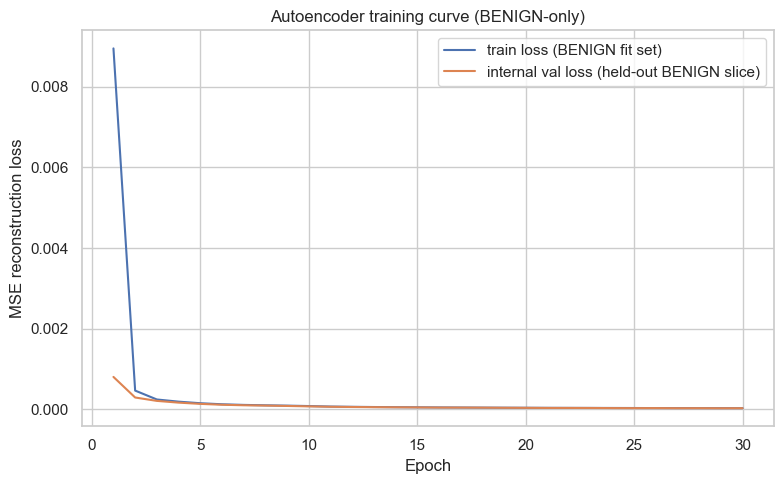

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, len(history["train_loss"]) + 1), history["train_loss"], label="train loss (BENIGN fit set)")
ax.plot(range(1, len(history["val_loss"]) + 1), history["val_loss"], label="internal val loss (held-out BENIGN slice)")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE reconstruction loss")
ax.set_title("Autoencoder training curve (BENIGN-only)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Score the validation set (full mixed) — reconstruction error

Reconstruction error (per-row MSE across all 80 features) computed on the full, untouched
`cicids2017_features_val.parquet` (BENIGN + every attack type) -- this is the anomaly-scoring
step, entirely separate from the training-time internal BENIGN validation loss in §5.

In [14]:
X_val_full = val_df[feature_cols].to_numpy(dtype=np.float32)

reconstruction_error_val = compute_reconstruction_error(model, X_val_full)

val_scored = val_df[["Label"]].copy()
val_scored["reconstruction_error"] = reconstruction_error_val
val_scored["is_attack"] = (val_scored["Label"] != "BENIGN").astype(int)

print(val_scored.groupby("is_attack")["reconstruction_error"].describe())

              count      mean       std       min       25%       50%       75%       max
is_attack                                                                                
0          419012.0  0.000032  0.001333  0.000002  0.000002  0.000004  0.000011  0.828387
1           85148.0  0.004809  0.008452  0.000002  0.000010  0.000535  0.003856  0.056300


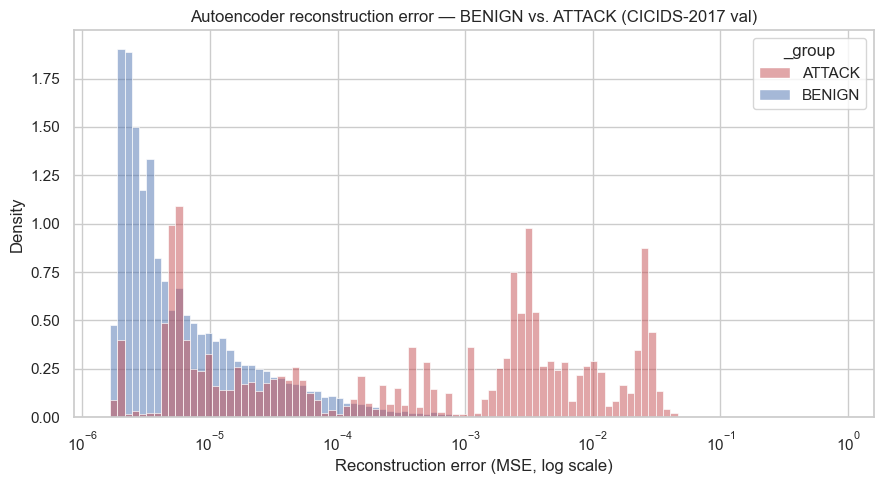

In [15]:
val_scored["_group"] = np.where(val_scored["Label"] == "BENIGN", "BENIGN", "ATTACK")

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(
    data=val_scored, x="reconstruction_error", hue="_group",
    stat="density", common_norm=False, bins=100, log_scale=(True, False), ax=ax,
    palette={"BENIGN": "#4C72B0", "ATTACK": "#C44E52"},
)
ax.set_title("Autoencoder reconstruction error — BENIGN vs. ATTACK (CICIDS-2017 val)")
ax.set_xlabel("Reconstruction error (MSE, log scale)")
plt.tight_layout()
plt.show()

## 7. Choose a threshold and evaluate

Small threshold sweep, mirroring `01_isolation_forest.ipynb`'s contamination sweep:
candidate cutoffs are the 90th/95th/99th percentiles of the **val-set BENIGN**
reconstruction-error distribution (the distribution plotted above), evaluated against
Precision/Recall/F1 on the full mixed val set. AUC-ROC uses the continuous reconstruction
error directly and is therefore identical across all threshold candidates (ranking, not
cutoff, determines it) -- included once per row for completeness, same convention as the
Isolation Forest sweep table.

In [16]:
benign_val_errors = val_scored.loc[val_scored["Label"] == "BENIGN", "reconstruction_error"]
auc_roc_ae = roc_auc_score(val_scored["is_attack"], val_scored["reconstruction_error"])

sweep_rows = []
for pct in THRESHOLD_PERCENTILES:
    threshold = float(np.percentile(benign_val_errors, pct))
    pred = (val_scored["reconstruction_error"] > threshold).astype(int)
    sweep_rows.append({
        "percentile": pct,
        "threshold": threshold,
        "precision": precision_score(val_scored["is_attack"], pred),
        "recall": recall_score(val_scored["is_attack"], pred),
        "f1": f1_score(val_scored["is_attack"], pred),
        "auc_roc": auc_roc_ae,
    })

sweep_df = pd.DataFrame(sweep_rows)
sweep_df

,percentile,threshold,precision,recall,f1,auc_roc
0,90,0.000038,0.568634,0.648706,0.606037,0.864104
1,95,0.000083,0.708662,0.598511,0.648945,0.864104
2,99,0.000405,0.913755,0.521480,0.664010,0.864104


In [17]:
best_row = sweep_df.loc[sweep_df["f1"].idxmax()]
CHOSEN_THRESHOLD = float(best_row["threshold"])
CHOSEN_PERCENTILE = int(best_row["percentile"])
print(f"Chosen threshold: {CHOSEN_THRESHOLD:.6f}  ({CHOSEN_PERCENTILE}th percentile of val-BENIGN reconstruction error)  F1={best_row['f1']:.4f}")

final_prediction = (val_scored["reconstruction_error"] > CHOSEN_THRESHOLD).astype(int)
val_scored["prediction"] = final_prediction

final_precision = precision_score(val_scored["is_attack"], final_prediction)
final_recall = recall_score(val_scored["is_attack"], final_prediction)
final_f1 = f1_score(val_scored["is_attack"], final_prediction)

print(f"\nFinal (chosen threshold) -- Precision {final_precision:.4f}  Recall {final_recall:.4f}  "
      f"F1 {final_f1:.4f}  AUC-ROC {auc_roc_ae:.4f}")

Chosen threshold: 0.000405  (99th percentile of val-BENIGN reconstruction error)  F1=0.6640

Final (chosen threshold) -- Precision 0.9138  Recall 0.5215  F1 0.6640  AUC-ROC 0.8641


## 8. Per-category recall breakdown

In [18]:
attack_rows = val_scored[val_scored["Label"] != "BENIGN"].copy()

category_recall_ae = (
    attack_rows.groupby("Label")
    .agg(recall=("prediction", "mean"), n_rows=("prediction", "size"))
    .sort_values("recall")
)
category_recall_ae

,recall,n_rows
Label,,
SSH-Patator,0.000000,644
Web Attack - Sql Injection,0.000000,4
Web Attack - XSS,0.000000,131
FTP-Patator,0.000843,1186
PortScan,0.002701,18139
Web Attack - Brute Force,0.003401,294
Bot,0.023136,389
Infiltration,0.285714,7
DDoS,0.492989,25603


## 9. Three-way comparison to Isolation Forest and Random Forest

Positional join against `cicids2017_isoforest_scores_val.parquet` and
`cicids2017_rf_scores_val.parquet` (both `row_index`-aligned to `cicids2017_features_val.parquet`,
same convention `02_random_forest.ipynb` already used to pull in Isolation Forest's scores) --
avoids reloading or re-running either model, keeping both prior notebooks untouched.

In [19]:
isoforest_scores_val = pd.read_parquet(DATA_FEATURES_DIR / "cicids2017_isoforest_scores_val.parquet")
rf_scores_val = pd.read_parquet(DATA_FEATURES_DIR / "cicids2017_rf_scores_val.parquet")
assert len(isoforest_scores_val) == len(val_df) == len(rf_scores_val), "all three score files must align row-for-row with val_df"

three_way_df = val_df[["Label"]].copy()
three_way_df["if_prediction"] = isoforest_scores_val["prediction"].to_numpy()
three_way_df["rf_prediction"] = rf_scores_val["prediction"].to_numpy()
three_way_df["ae_prediction"] = val_scored["prediction"].to_numpy()

attack_rows3 = three_way_df[three_way_df["Label"] != "BENIGN"]
three_way_recall = (
    attack_rows3.groupby("Label")[["if_prediction", "rf_prediction", "ae_prediction"]].mean()
    .rename(columns={
        "if_prediction": "isolation_forest_recall",
        "rf_prediction": "random_forest_recall",
        "ae_prediction": "autoencoder_recall",
    })
)
three_way_recall["n_rows"] = attack_rows3.groupby("Label").size()
three_way_recall = three_way_recall.sort_values("autoencoder_recall")
three_way_recall

,isolation_forest_recall,random_forest_recall,autoencoder_recall,n_rows
Label,,,,
SSH-Patator,0.000000,0.989130,0.000000,644
Web Attack - Sql Injection,0.000000,0.750000,0.000000,4
Web Attack - XSS,0.000000,0.954198,0.000000,131
FTP-Patator,0.000000,1.000000,0.000843,1186
PortScan,0.002371,0.990463,0.002701,18139
Web Attack - Brute Force,0.054422,0.982993,0.003401,294
Bot,0.023136,0.889460,0.023136,389
Infiltration,0.857143,0.714286,0.285714,7
DDoS,0.573136,0.999805,0.492989,25603


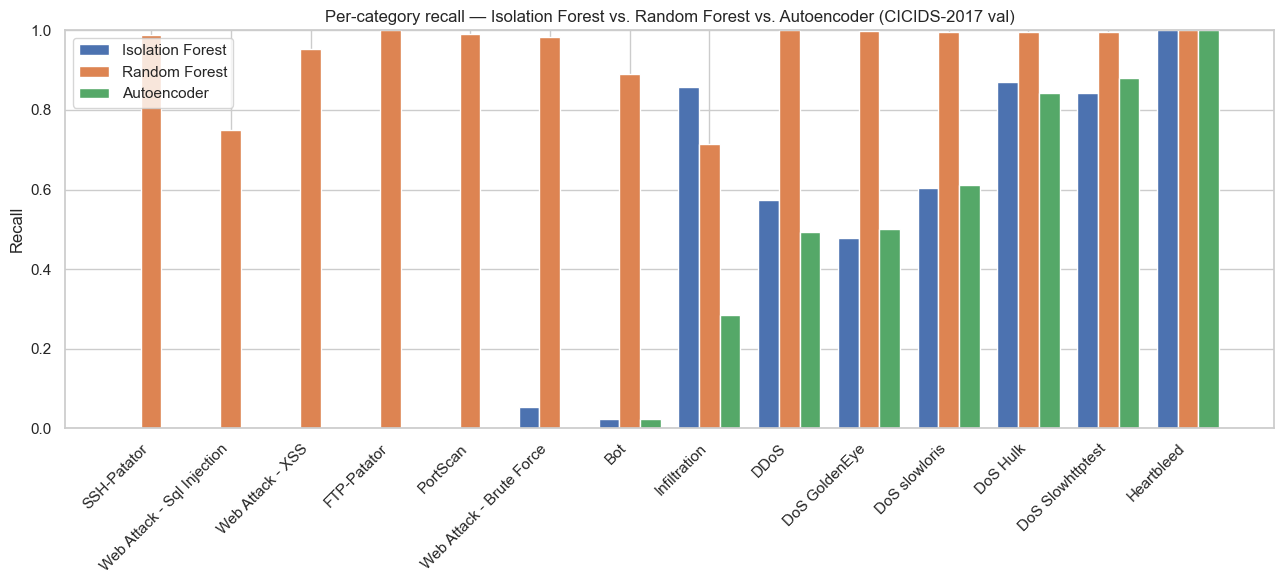

In [20]:
fig, ax = plt.subplots(figsize=(13, 6))
categories_plot = three_way_recall.index.tolist()
x = np.arange(len(categories_plot))
width = 0.26

ax.bar(x - width, three_way_recall["isolation_forest_recall"], width, label="Isolation Forest", color="#4C72B0")
ax.bar(x, three_way_recall["random_forest_recall"], width, label="Random Forest", color="#DD8452")
ax.bar(x + width, three_way_recall["autoencoder_recall"], width, label="Autoencoder", color="#55A868")

ax.set_xticks(x)
ax.set_xticklabels(categories_plot, rotation=45, ha="right")
ax.set_ylabel("Recall")
ax.set_ylim(0, 1)
ax.set_title("Per-category recall — Isolation Forest vs. Random Forest vs. Autoencoder (CICIDS-2017 val)")
ax.legend()
plt.tight_layout()
plt.show()

In [21]:
diversity_corr = three_way_recall[["isolation_forest_recall", "autoencoder_recall"]].corr().iloc[0, 1]
print(f"Correlation between Isolation Forest and Autoencoder per-category recall "
      f"across {len(three_way_recall)} attack categories: {diversity_corr:.3f}")
print()
print("High positive correlation -> Autoencoder's blind spots mirror Isolation Forest's closely "
      "(redundant unsupervised diversity, since both would need Random Forest to cover the same gaps).")
print("Low/negative correlation -> Autoencoder catches categories Isolation Forest misses (or vice "
      "versa), which is real added diversity for the Fusion Layer's unsupervised half.")

Correlation between Isolation Forest and Autoencoder per-category recall across 14 attack categories: 0.925

High positive correlation -> Autoencoder's blind spots mirror Isolation Forest's closely (redundant unsupervised diversity, since both would need Random Forest to cover the same gaps).
Low/negative correlation -> Autoencoder catches categories Isolation Forest misses (or vice versa), which is real added diversity for the Fusion Layer's unsupervised half.


## 10. Zero-day (LOAO) evaluation

Same 10 categories, same fold structure as `01_isolation_forest.ipynb` / `02_random_forest.ipynb`.
Two design decisions specific to the Autoencoder are flagged explicitly below rather than assumed:

1. **Feature count**: the LOAO parquet files (`preprocess_pipeline.py`'s output) predate
   `feature_extractor.py` entirely -- they carry the 78 raw CICFlowMeter columns only, **no**
   sentinel-missing-flag columns and no CTI columns. So LOAO folds here use **78** features,
   not 80. This is not a new inconsistency introduced by this notebook -- it's the same
   precedent Isolation Forest's and Random Forest's LOAO folds already established.
2. **Per-fold scaling**: unlike Isolation Forest and Random Forest (both tree-based and
   scale-invariant, so training on raw unscaled LOAO folds was fine), the Autoencoder's
   weights **are** sensitive to feature scale. Since the LOAO files are raw/unscaled, a
   `MinMaxScaler` must be fit fresh per fold. Decision: fit it on the fold's full training
   data (all classes, before filtering to BENIGN) -- matching `feature_extractor.py`'s actual
   convention of fitting the scaler on the full train split, not a BENIGN-only subset -- then
   apply that same fitted scaler to both the BENIGN-only rows used for Autoencoder training
   and to the fold's zero-day test set.

The fold's own detection threshold is also recomputed per fold (same `CHOSEN_PERCENTILE` from
§7, applied to that fold's own held-out BENIGN internal-validation reconstruction-error
distribution) rather than reusing the main model's raw numeric threshold -- each fold has its
own scaler and its own reconstruction-error scale, so the raw threshold value from §7 isn't
transferable across folds, only the percentile rule is.

In [22]:
SENTINEL_COLS_LOAO = ["Init_Win_bytes_forward", "Init_Win_bytes_backward"]
NON_FEATURE_COLS_LOAO = ["Label"]  # LOAO raw files carry no MITRE/CTI columns at all

def select_raw_feature_columns(df):
    return [c for c in df.columns if c not in NON_FEATURE_COLS_LOAO and pd.api.types.is_numeric_dtype(df[c])]

_sample_loao = pd.read_parquet(LOAO_DIR / "loao_bot_train.parquet")
_loao_feature_cols_preview = select_raw_feature_columns(_sample_loao)
print(f"LOAO raw feature count: {len(_loao_feature_cols_preview)} "
      f"(78, not 80 -- no sentinel-missing-flag or CTI columns exist in these files, "
      f"same precedent Isolation Forest's and Random Forest's LOAO folds already used).")

LOAO raw feature count: 78 (78, not 80 -- no sentinel-missing-flag or CTI columns exist in these files, same precedent Isolation Forest's and Random Forest's LOAO folds already used).


In [23]:
CATEGORIES = [
    ("DoS Hulk", "dos_hulk"),
    ("PortScan", "portscan"),
    ("DDoS", "ddos"),
    ("DoS GoldenEye", "dos_goldeneye"),
    ("FTP-Patator", "ftp_patator"),
    ("SSH-Patator", "ssh_patator"),
    ("DoS slowloris", "dos_slowloris"),
    ("DoS Slowhttptest", "dos_slowhttptest"),
    ("Bot", "bot"),
    ("Web Attack - Brute Force", "web_attack_brute_force"),
]

loao_ae_results = []
_loao_loop_start = time.perf_counter()

for display_name, slug in CATEGORIES:
    _fold_start = time.perf_counter()
    loao_train_df = pd.read_parquet(LOAO_DIR / f"loao_{slug}_train.parquet")
    loao_test_df = pd.read_parquet(LOAO_DIR / f"loao_{slug}_zeroday_test.parquet")

    # Train-only sentinel imputation, same convention as the other two notebooks' LOAO folds.
    for c in SENTINEL_COLS_LOAO:
        median = loao_train_df[c].median(skipna=True)
        loao_train_df[c] = loao_train_df[c].fillna(median)
        loao_test_df[c] = loao_test_df[c].fillna(median)

    fold_feature_cols = select_raw_feature_columns(loao_train_df)

    # Fit scaler on the FOLD'S FULL training data (all classes), matching feature_extractor.py's
    # actual convention -- not a BENIGN-only fit.
    fold_scaler = MinMaxScaler()
    fold_scaler.fit(loao_train_df[fold_feature_cols])
    loao_train_scaled = loao_train_df.copy()
    loao_test_scaled = loao_test_df.copy()
    loao_train_scaled[fold_feature_cols] = fold_scaler.transform(loao_train_df[fold_feature_cols])
    loao_test_scaled[fold_feature_cols] = fold_scaler.transform(loao_test_df[fold_feature_cols])

    fold_benign_train_df = loao_train_scaled[loao_train_scaled["Label"] == "BENIGN"]
    fold_benign_fit_df, fold_benign_internal_val_df = train_test_split(
        fold_benign_train_df, test_size=BENIGN_INTERNAL_VAL_FRAC, random_state=RANDOM_STATE
    )

    X_fold_fit = fold_benign_fit_df[fold_feature_cols].to_numpy(dtype=np.float32)
    X_fold_internal_val = fold_benign_internal_val_df[fold_feature_cols].to_numpy(dtype=np.float32)

    fold_model, fold_history = train_autoencoder(
        X_fold_fit, X_fold_internal_val, input_dim=len(fold_feature_cols), config=AE_CONFIG, verbose=False
    )

    X_fold_test = loao_test_scaled[fold_feature_cols].to_numpy(dtype=np.float32)
    fold_test_errors = compute_reconstruction_error(fold_model, X_fold_test)

    # Threshold: same percentile rule as §7, recomputed against THIS fold's own held-out
    # BENIGN internal-validation errors (never against the zero-day test set itself).
    fold_internal_val_errors = compute_reconstruction_error(fold_model, X_fold_internal_val)
    fold_threshold = float(np.percentile(fold_internal_val_errors, CHOSEN_PERCENTILE))

    fold_pred_attack = (fold_test_errors > fold_threshold).astype(int)
    fold_y_true = (loao_test_scaled["Label"] != "BENIGN").astype(int).to_numpy()

    tp = int(((fold_pred_attack == 1) & (fold_y_true == 1)).sum())
    fn = int(((fold_pred_attack == 0) & (fold_y_true == 1)).sum())
    fp = int(((fold_pred_attack == 1) & (fold_y_true == 0)).sum())
    tn = int(((fold_pred_attack == 0) & (fold_y_true == 0)).sum())

    fold_recall = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
    fold_fpr = fp / (fp + tn) if (fp + tn) > 0 else float("nan")

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    fold_seconds = time.perf_counter() - _fold_start

    loao_ae_results.append({
        "category": display_name,
        "recall": fold_recall,
        "fpr": fold_fpr,
        "n_test_rows": len(loao_test_df),
        "n_attack_rows": int(fold_y_true.sum()),
        "n_benign_rows": int((fold_y_true == 0).sum()),
        "threshold": fold_threshold,
        "epochs_run": len(fold_history["train_loss"]),
        "fold_seconds": fold_seconds,
    })

    print(f"{display_name:30s}  recall={fold_recall:.4f}  fpr={fold_fpr:.4f}  "
          f"n_test={len(loao_test_df)}  epochs_run={len(fold_history['train_loss'])}  "
          f"time={fold_seconds:.2f}s")

loao_loop_seconds = time.perf_counter() - _loao_loop_start
print(f"\nFull LOAO loop ({len(CATEGORIES)} folds) wall-clock time: {loao_loop_seconds:.2f}s (device={DEVICE})")

loao_ae_summary_df = pd.DataFrame(loao_ae_results).sort_values("recall").reset_index(drop=True)

DoS Hulk                        recall=0.8478  fpr=0.0093  n_test=591858  epochs_run=30  time=325.53s


PortScan                        recall=0.0110  fpr=0.0093  n_test=509706  epochs_run=30  time=309.04s


DDoS                            recall=0.5552  fpr=0.0092  n_test=547026  epochs_run=30  time=332.97s


DoS GoldenEye                   recall=0.4862  fpr=0.0093  n_test=429298  epochs_run=30  time=358.59s


FTP-Patator                     recall=0.0008  fpr=0.0097  n_test=424943  epochs_run=30  time=308.35s


SSH-Patator                     recall=0.0006  fpr=0.0094  n_test=422231  epochs_run=30  time=322.31s


DoS slowloris                   recall=0.5812  fpr=0.0094  n_test=424397  epochs_run=30  time=324.65s


DoS Slowhttptest                recall=0.9254  fpr=0.0095  n_test=424240  epochs_run=30  time=332.33s


Bot                             recall=0.0226  fpr=0.0092  n_test=420960  epochs_run=30  time=435.63s


Web Attack - Brute Force        recall=0.0020  fpr=0.0094  n_test=420482  epochs_run=30  time=323.88s

Full LOAO loop (10 folds) wall-clock time: 3373.29s (device=cuda)


In [24]:
loao_ae_summary_df

,category,recall,fpr,n_test_rows,n_attack_rows,n_benign_rows,threshold,epochs_run,fold_seconds
0,SSH-Patator,0.000621,0.009401,422231,3219,419012,0.000351,30,322.314001
1,FTP-Patator,0.000843,0.009744,424943,5931,419012,0.000399,30,308.354065
2,Web Attack - Brute Force,0.002041,0.009386,420482,1470,419012,0.000288,30,323.884835
3,PortScan,0.010960,0.009284,509706,90694,419012,0.000229,30,309.037420
4,Bot,0.022587,0.009248,420960,1948,419012,0.000321,30,435.626952
5,DoS GoldenEye,0.486195,0.009281,429298,10286,419012,0.000291,30,358.586880
6,DDoS,0.555221,0.009241,547026,128014,419012,0.000228,30,332.974616
7,DoS slowloris,0.581244,0.009444,424397,5385,419012,0.000415,30,324.647668
8,DoS Hulk,0.847830,0.009317,591858,172846,419012,0.000246,30,325.526128
9,DoS Slowhttptest,0.925402,0.009489,424240,5228,419012,0.000330,30,332.327111


### Three-way LOAO comparison

`reports/isolation_forest_loao_results.csv`'s `current_contamination_tuned` rows and
`reports/random_forest_loao_results.csv` against this notebook's own LOAO results.

In [25]:
if_loao = pd.read_csv(REPORTS_DIR / "isolation_forest_loao_results.csv")
if_loao_tuned = if_loao[if_loao["status"] == "current_contamination_tuned"].set_index("category")
rf_loao = pd.read_csv(REPORTS_DIR / "random_forest_loao_results.csv").set_index("category")
ae_loao_idx = loao_ae_summary_df.set_index("category")

category_order = [c for c, _ in CATEGORIES]
three_way_loao_df = pd.DataFrame({
    "isolation_forest_recall": if_loao_tuned["recall"],
    "random_forest_recall": rf_loao["recall"],
    "autoencoder_recall": ae_loao_idx["recall"],
}).loc[category_order]
three_way_loao_df.sort_values("autoencoder_recall")

,isolation_forest_recall,random_forest_recall,autoencoder_recall
category,,,
SSH-Patator,0.003417,0.006524,0.000621
FTP-Patator,0.000843,0.312763,0.000843
Web Attack - Brute Force,0.050340,0.853061,0.002041
PortScan,0.002018,0.001665,0.010960
Bot,0.023101,0.000000,0.022587
DoS GoldenEye,0.729827,0.169065,0.486195
DDoS,0.634806,0.616565,0.555221
DoS slowloris,0.613185,0.688208,0.581244
DoS Hulk,0.900414,0.011583,0.847830


In [26]:
loao_diversity_corr = three_way_loao_df[["isolation_forest_recall", "autoencoder_recall"]].corr().iloc[0, 1]
print(f"LOAO correlation between Isolation Forest and Autoencoder recall across "
      f"{len(three_way_loao_df)} held-out categories: {loao_diversity_corr:.3f}")

LOAO correlation between Isolation Forest and Autoencoder recall across 10 held-out categories: 0.977


## 11. Save the model + results

In [27]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODELS_DIR / "autoencoder.pt"
torch.save(model.state_dict(), model_path)
print("Saved model state dict to", model_path)

config_to_save = dict(AE_CONFIG)
config_to_save.update({
    "input_dim": len(feature_cols),
    "chosen_threshold": CHOSEN_THRESHOLD,
    "chosen_percentile": CHOSEN_PERCENTILE,
    "random_state": RANDOM_STATE,
    "benign_internal_val_frac": BENIGN_INTERNAL_VAL_FRAC,
    "epochs_run": len(history["train_loss"]),
})
config_path = MODELS_DIR / "autoencoder_config.json"
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config_to_save, f, indent=2)
print("Saved config to", config_path)

Saved model state dict to E:\thesis\models\autoencoder.pt
Saved config to E:\thesis\models\autoencoder_config.json


In [28]:
val_metrics_path = REPORTS_DIR / "autoencoder_val_metrics.csv"
with open(val_metrics_path, "w", encoding="utf-8") as f:
    f.write("# threshold sweep (candidate percentiles of val-set BENIGN reconstruction error)\n")
    sweep_df.to_csv(f, index=False)
    f.write(f"\n# chosen: percentile={CHOSEN_PERCENTILE}, threshold={CHOSEN_THRESHOLD}\n")
    f.write("# final metrics at chosen threshold\n")
    pd.DataFrame([{
        "precision": final_precision, "recall": final_recall, "f1": final_f1, "auc_roc": auc_roc_ae,
    }]).to_csv(f, index=False)
    f.write("\n# per-category (attack classes only)\n")
    category_recall_ae.reset_index().rename(columns={"Label": "category"}).to_csv(f, index=False)

print("Saved val metrics to", val_metrics_path)

Saved val metrics to E:\thesis\reports\autoencoder_val_metrics.csv


In [29]:
loao_csv_path = REPORTS_DIR / "autoencoder_loao_results.csv"
loao_ae_summary_df.to_csv(loao_csv_path, index=False)
print("Saved LOAO summary to", loao_csv_path)

Saved LOAO summary to E:\thesis\reports\autoencoder_loao_results.csv


In [30]:
# row_index: position within cicids2017_features_val.parquet (0..N-1), same convention as
# the Isolation Forest / Random Forest score files, so this can be joined positionally against
# them in the Fusion Layer.
rf_ae_scores_df = pd.DataFrame({
    "row_index": val_df.index.to_numpy(),
    "reconstruction_error": reconstruction_error_val,
    "prediction": val_scored["prediction"].to_numpy(),
})

scores_path = DATA_FEATURES_DIR / "cicids2017_autoencoder_scores_val.parquet"
rf_ae_scores_df.to_parquet(scores_path, index=False)
print("Saved val-set scores to", scores_path)
rf_ae_scores_df.head()

Saved val-set scores to E:\thesis\data\features\cicids2017_autoencoder_scores_val.parquet


,row_index,reconstruction_error,prediction
0,0,0.001827,1
1,1,0.000127,0
2,2,0.000004,0
3,3,0.000002,0
4,4,0.000003,0
